In [1]:
from pathlib import Path
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from softtools.bit_op import BitPack

c:\Users\Steve\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\lib\_arraysetops_impl.py:1027: RuntimeWarning: invalid value encountered in equal
  mask |= (ar1 == a)


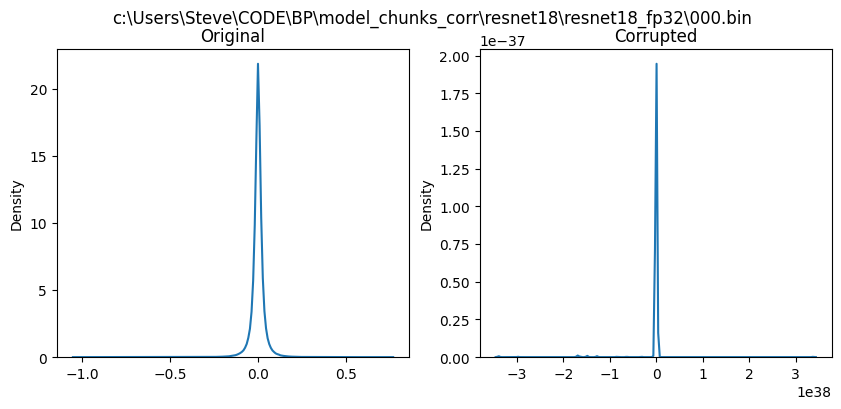

In [2]:
org = Path.cwd() / "model_chunks_corr/resnet18/resnet18_fp32/"

for i in sorted(org.rglob("*.bin")):
    orig = (
        Path.cwd() / "model_chunks" / i.parent.parent.stem / i.parent.stem / i.name
    ).read_bytes()
    corr = i.read_bytes()

    
    fig,axs = plt.subplots(1,2,figsize=(10, 4))
    orig = np.frombuffer(orig, dtype=np.float32)
    corr = np.frombuffer(corr, dtype=np.float32)
    
    sns.kdeplot(orig,ax=axs[0])
    sns.kdeplot(corr,ax=axs[1])
    
    axs[0].set_title("Original")
    axs[1].set_title("Corrupted")
    plt.suptitle(i)
    plt.show()
    break